# Plantilla y Generador de Gráficos Estandarizados (Informe Villa Gaucho)

Este cuaderno implementa el generador completo de gráficos con los formatos y estándares del **Informe de Villa Gaucho**, incorporando las pautas de estilo solicitadas:

1. **Tamaño de letra uniforme 14**:
   - Títulos, ejes, porcentajes, etiquetas de categorías, cantidades numéricas y llamadas/flechas con fuente tamaño **14**.
2. **Gráficos de Torta**:
   - Ordenados de mayor a menor porcentaje.
   - Secuencia estricta de colores:
     1. **Azul** (`#4285F4`)
     2. **Naranja** (`#FB8C00`)
     3. **Verde** (`#34A853`)
     4. **Amarillo** (`#FBBC05`)
     5. **Violeta** (`#8E24AA`)
     6. **Beige** (`#D7CCC8`)
   - Para preguntas binarias (Positivo / Negativo, ej: Sí / No): **Positivo = Azul (`#4285F4`)**, **Negativo = Naranja (`#FB8C00`)**.
   - Líneas guía (callouts) con punto conector gris (`#8c8c8c`), nombre de la categoría y subtexto con la cantidad (ej. "X personas" / "X hogares").
3. **Gráficos de Barras**:
   - Azul institucional del informe de Villa Gaucho (`#4285F4`).
   - Para variables cualitativas o cuantitativas discretas: barras horizontales con el conteo en negrita dentro de la barra y el porcentaje `X,X%` a la derecha.
   - Si se requiere colorear las barras por categoría, se utiliza exactamente la misma paleta que en el gráfico de torta.
   - Para variables continuas agrupadas en intervalos: histograma/barras con borde definido y etiquetas de frecuencia y porcentaje centradas arriba.


In [11]:
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración global de matplotlib: tamaño de fuente 14
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.titlesize'] = 14

# ==========================================
# PALETA DE COLORES ESTANDARIZADA
# ==========================================
# Para torta: 1. Azul, 2. Naranja, 3. Verde, 4. Amarillo, 5. Violeta, 6. Beige
PALETA_TORTA = [
    '#4285F4',  # 1. Azul (Google / Villa Gaucho)
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Color azul estándar para gráficos de barras del informe
COLOR_AZUL_INFORME = '#4285F4'

# Colores para preguntas binarias (Positivo / Negativo)
COLOR_POSITIVO = '#4285F4'  # Azul
COLOR_NEGATIVO = '#FB8C00'  # Naranja


## 1. Función para Gráfico de Torta Estandarizado
- Ordena automáticamente de **mayor a menor** frecuencia.
- Asigna la secuencia: **Azul, Naranja, Verde, Amarillo, Violeta, Beige**.
- Si es pregunta binaria (`es_binario=True`), asigna **Azul a Positivo** y **Naranja a Negativo**.
- Tamaño de fuente **14** en porcentajes internos, etiquetas externas y cantidades.
- Formato de señalización idéntico a Villa Gaucho con línea conector y punto guía.


In [12]:
def graficar_torta(categorias, valores, titulo="", unidad="personas", es_binario=False, orden_positivo_primero=True, figsize=(10, 6)):
    """
    Genera un gráfico de torta con el formato del Informe de Villa Gaucho:
    - Paleta ordenada de mayor a menor: Azul, Naranja, Verde, Amarillo, Violeta, Beige.
    - Si es binario (Sí/No): Positivo = Azul, Negativo = Naranja.
    - Tamaño de fuente 14 en todas las anotaciones.
    - Señalizaciones externas con punto conector gris y flecha guía.
    """
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})
    
    if es_binario:
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']
        
        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        # Ordenar de mayor porcentaje/frecuencia a menor
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values
    total = sum(vals)

    # Configurar figura
    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    wedges, texts, autotexts = ax.pie(
        vals,
        autopct=lambda p: f"{p:.1f}%".replace('.', ','),
        pctdistance=0.72,
        colors=colores,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=1, edgecolor='white', linewidth=1.5)
    )

    # Estilo porcentajes interiores (tamaño 14)
    for at in autotexts:
        at.set_color('#1a1a1a')
        at.set_fontsize(14)
        at.set_fontweight('bold')

    # Líneas guía externas con punto gris y descripción
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        y = np.sin(np.deg2rad(ang))
        x = np.cos(np.deg2rad(ang))

        # Punto sobre la cuña
        x_punto, y_punto = 0.85 * x, 0.85 * y

        # Posición externa
        lado = -1 if x < 0 else 1
        x_afuera = 1.35 * lado
        y_afuera = 1.15 * y

        # Punto gris conector
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#8c8c8c')

        # Texto de cantidad singular / plural
        cant = int(vals[i])
        palabra_unidad = unidad[:-1] if (cant == 1 and unidad.endswith('s')) else unidad
        texto_unidad = f"{cant} {palabra_unidad}"

        # Anotación externa con flecha
        ax.annotate(
            f"{cats[i]}\n",
            xy=(x_punto, y_punto),
            xytext=(x_afuera, y_afuera),
            horizontalalignment="right" if lado == -1 else "left",
            verticalalignment="center",
            fontsize=14,
            color="#202124",
            fontweight='medium',
            arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.2)
        )

        # Subtexto de cantidad (tamaño 14)
        ax.text(
            x_afuera,
            y_afuera - 0.13,
            texto_unidad,
            horizontalalignment="right" if lado == -1 else "left",
            verticalalignment="center",
            fontsize=14,
            color="#70757a"
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=20, fontweight='bold', color='#202124')

    ax.set_xlim(-1.95, 1.95)
    ax.set_ylim(-1.35, 1.35)
    plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
    plt.show()


### Ejemplos de uso del Gráfico de Torta
1. **Ejemplo 1**: Torta multicategoría ordenada de mayor a menor con los 6 colores solicitados.
2. **Ejemplo 2**: Pregunta binaria (Sí/No) con Positivo en Azul y Negativo en Naranja.


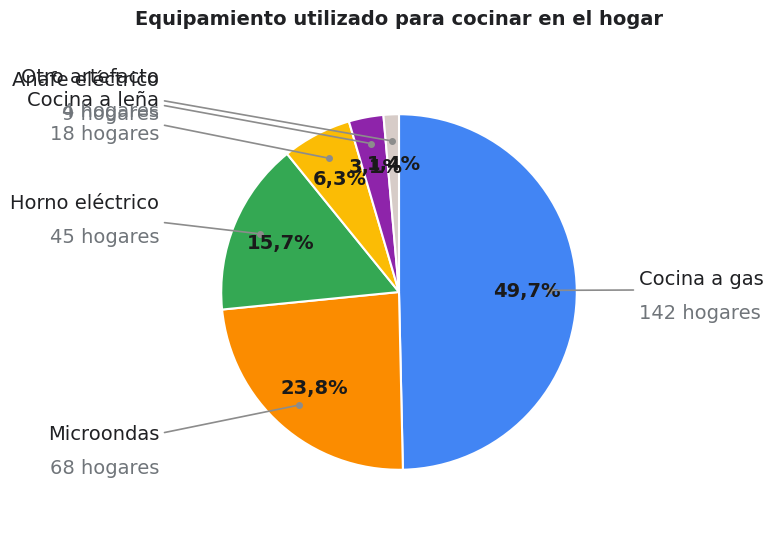

In [13]:
# Ejemplo 1: Torta de 6 categorías ordenada de mayor a menor porcentaje
categorias_ejemplo = [
    'Cocina a gas',
    'Microondas',
    'Horno eléctrico',
    'Cocina a leña',
    'Anafe eléctrico',
    'Otro artefacto'
]
valores_ejemplo = [142, 68, 45, 18, 9, 4]

graficar_torta(
    categorias=categorias_ejemplo,
    valores=valores_ejemplo,
    titulo="Equipamiento utilizado para cocinar en el hogar",
    unidad="hogares"
)


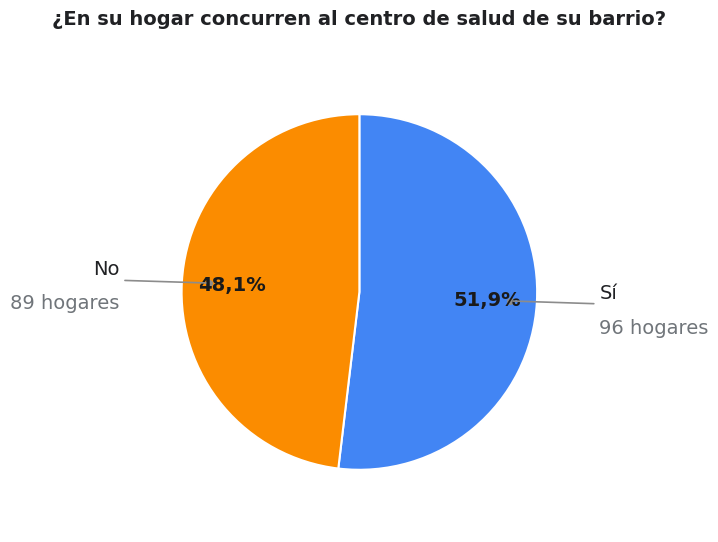

In [14]:
# Ejemplo 2: Pregunta binaria (Positivo = Azul, Negativo = Naranja)
respuestas_binarias = ['Sí', 'No']
frecuencias_binarias = [96, 89]

graficar_torta(
    categorias=respuestas_binarias,
    valores=frecuencias_binarias,
    titulo="¿En su hogar concurren al centro de salud de su barrio?",
    unidad="hogares",
    es_binario=True
)


## 2. Gráfico de Barras Horizontales (Cualitativas y Cuantitativas Discretas)
- Color estándar: **Azul Villa Gaucho (`#4285F4`)**.
- Opción `usar_colores_torta=True` para replicar exactamente la paleta de la torta si las barras van coloreadas por categoría.
- Cantidades absolutas en blanco dentro de las barras y porcentajes `X,X%` a la derecha.
- Cuadrícula suave punteada en el eje X.
- Tamaño de fuente **14** en todas las señalizaciones, valores y títulos.


In [15]:
def graficar_barras_horizontales(etiquetas, valores, titulo="", xlabel="Cantidad de respuestas", ylabel="", sufijo_etiqueta="", usar_colores_torta=False, figsize=(12, 6)):
    """
    Genera un gráfico de barras horizontales idéntico al del informe Villa Gaucho:
    - Azul estándar (#4285F4) o paleta de torta si usar_colores_torta=True.
    - Valores absolutos dentro de las barras y porcentaje a la derecha.
    - Tipografía y señalizaciones en tamaño 14.
    """
    valores = np.array(valores, dtype=float)
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)

    fig, ax = plt.subplots(figsize=figsize)

    if usar_colores_torta:
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(n)]
    else:
        colores = COLOR_AZUL_INFORME

    barras = ax.barh(
        range(n),
        valores,
        color=colores,
        height=0.68,
        edgecolor='none'
    )

    # Etiquetas del eje Y (tamaño 14)
    ax.set_yticks(range(n))
    if sufijo_etiqueta:
        labels_y = [f"{lbl} {sufijo_etiqueta}" if int(lbl) != 1 else f"{lbl} {sufijo_etiqueta.rstrip('s')}" for lbl in etiquetas]
    else:
        labels_y = [str(lbl) for lbl in etiquetas]
    ax.set_yticklabels(labels_y, fontsize=14)

    # Cantidad y porcentaje a la derecha con tamaño 14
    max_val = max(valores) if len(valores) > 0 else 1
    offset_porcentaje = max_val * 0.035

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        x = barra.get_width()
        y = barra.get_y() + barra.get_height() / 2.0
        color_b = barra.get_facecolor()

        # Cantidad absoluta
        if x >= max_val * 0.08:
            ax.text(
                x / 2.0, y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
        else:
            ax.text(
                x + (max_val * 0.015), y, str(int(cantidad)),
                ha='left', va='center',
                color=color_b, fontweight='bold', fontsize=14
            )

        # Porcentaje a la derecha
        ax.text(
            x + offset_porcentaje, y,
            f"{porcentaje:.1f}%".replace('.', ','),
            ha='left', va='center',
            color='#202124', fontsize=14
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    # Escala y cuadrícula
    ax.set_xlim(0, max_val * 1.18)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


### Ejemplos de Gráficos de Barras Horizontales
1. **Ejemplo 1**: Cuantitativa discreta con azul estándar del informe.
2. **Ejemplo 2**: Cualitativa con `usar_colores_torta=True` usando los mismos colores que el gráfico de torta.


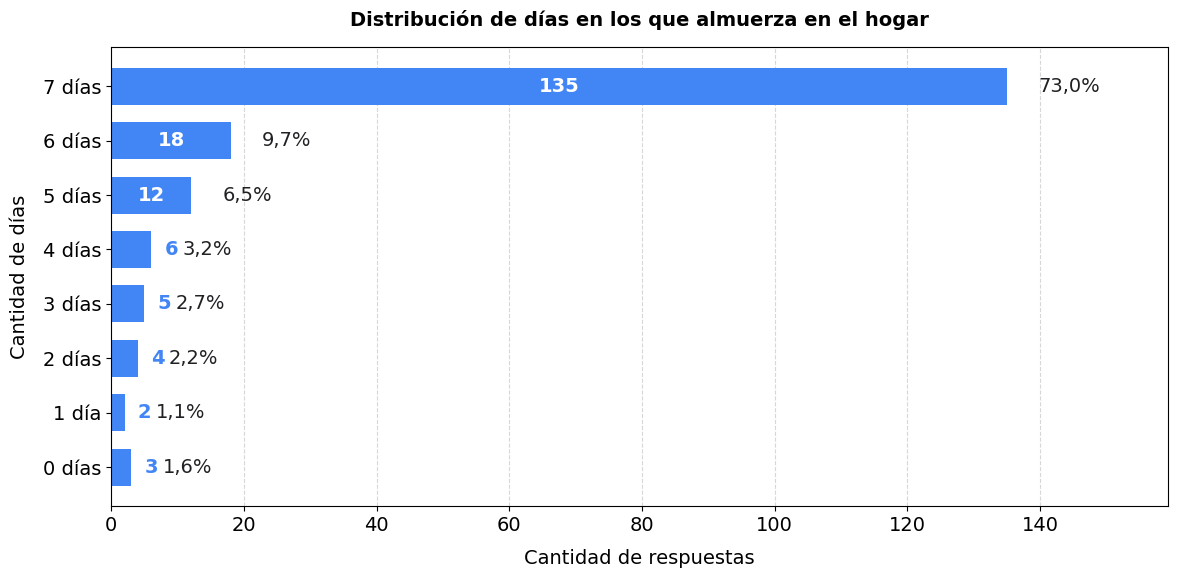

In [16]:
# Ejemplo 1: Variable cuantitativa discreta (días que almuerza en la semana)
dias = [0, 1, 2, 3, 4, 5, 6, 7]
respuestas_dias = [3, 2, 4, 5, 6, 12, 18, 135]

graficar_barras_horizontales(
    etiquetas=dias,
    valores=respuestas_dias,
    titulo="Distribución de días en los que almuerza en el hogar",
    xlabel="Cantidad de respuestas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días",
    usar_colores_torta=False  # Azul estándar Villa Gaucho
)


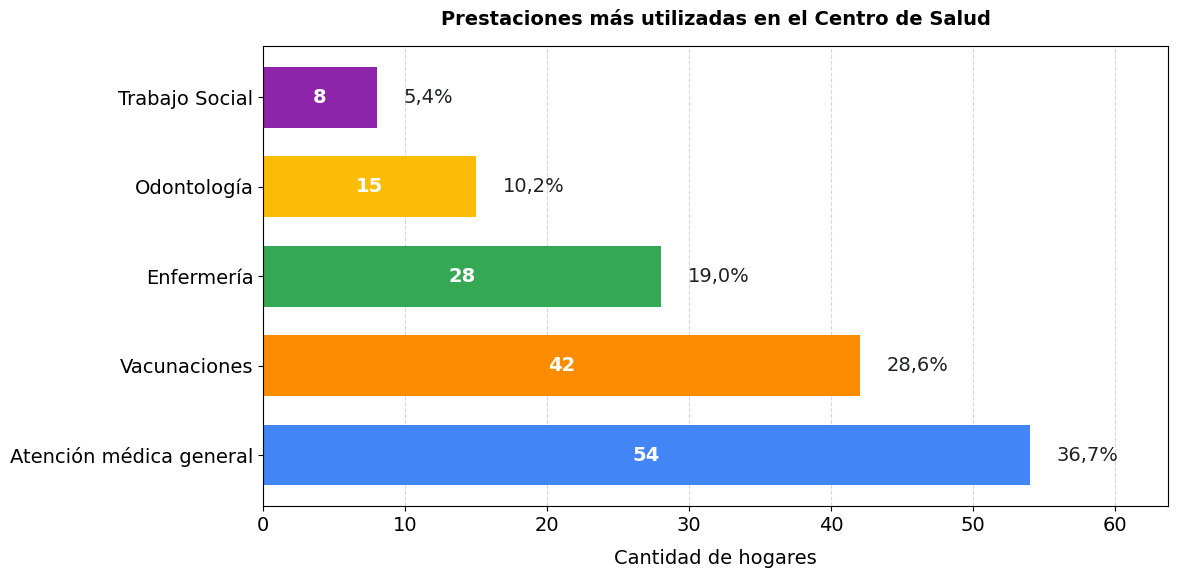

In [17]:
# Ejemplo 2: Variable cualitativa usando los mismos colores del gráfico de torta
prestaciones = ['Atención médica general', 'Vacunaciones', 'Enfermería', 'Odontología', 'Trabajo Social']
hogares_prestaciones = [54, 42, 28, 15, 8]

graficar_barras_horizontales(
    etiquetas=prestaciones,
    valores=hogares_prestaciones,
    titulo="Prestaciones más utilizadas en el Centro de Salud",
    xlabel="Cantidad de hogares",
    usar_colores_torta=True  # Mismos colores que la torta: Azul, Naranja, Verde, Amarillo, Violeta
)


## 3. Gráficos de Barras para Variables Cuantitativas Continuas (Agrupadas en Intervalos)
- Formato para intervalos de clase (como rangos de edad, años, ingresos).
- Barras en azul Villa Gaucho (`#4285F4`) con borde definido.
- Anotación de cantidad absoluta y porcentaje sobre cada barra con fuente tamaño **14**.


In [18]:
def graficar_barras_agrupadas_continuas(intervalos, frecuencias, titulo="", xlabel="Intervalos", ylabel="Cantidad de casos", figsize=(10, 6)):
    """
    Genera un gráfico de barras para variables cuantitativas continuas agrupadas por intervalos (estilo distribución/histograma).
    - Azul del informe (#4285F4).
    - Anotaciones de frecuencia y porcentaje centradas arriba de cada barra con fuente tamaño 14.
    """
    frecuencias = np.array(frecuencias, dtype=float)
    total = sum(frecuencias)
    porcentajes = (frecuencias / total) * 100 if total > 0 else np.zeros_like(frecuencias)
    x_pos = np.arange(len(intervalos))

    fig, ax = plt.subplots(figsize=figsize)

    barras = ax.bar(
        x_pos,
        frecuencias,
        color=COLOR_AZUL_INFORME,
        edgecolor='#2a62bc',
        linewidth=1.2,
        width=0.72
    )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(intervalos, fontsize=14, rotation=0)

    max_h = max(frecuencias) if len(frecuencias) > 0 else 1

    # Anotaciones arriba de cada barra en tamaño 14
    for barra, cant, pct in zip(barras, frecuencias, porcentajes):
        h = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2.0,
            h + (max_h * 0.02),
            f"{int(cant)}\n({pct:.1f}%)".replace('.', ','),
            ha='center', va='bottom',
            fontsize=14, color='#202124', fontweight='medium'
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_ylim(0, max_h * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


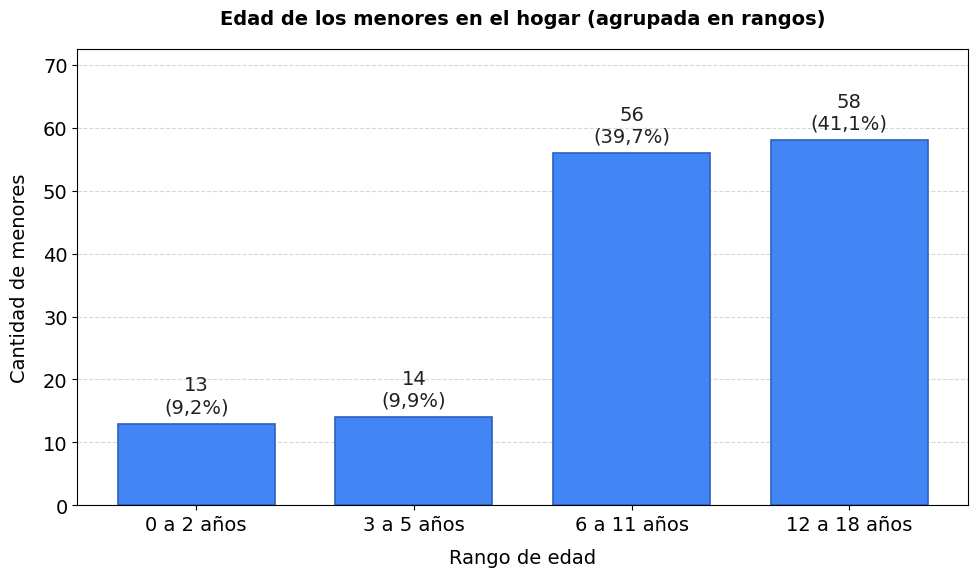

In [19]:
# Ejemplo: Rango de edad de menores en el hogar (variable agrupada por intervalos)
rangos_edad = ['0 a 2 años', '3 a 5 años', '6 a 11 años', '12 a 18 años']
cantidades_menores = [13, 14, 56, 58]

graficar_barras_agrupadas_continuas(
    intervalos=rangos_edad,
    frecuencias=cantidades_menores,
    titulo="Edad de los menores en el hogar (agrupada en rangos)",
    xlabel="Rango de edad",
    ylabel="Cantidad de menores"
)


## 4. Integración y uso directo con `datos.csv`
Ejemplo de cómo tomar una columna del archivo de datos del repositorio y graficarla automáticamente con las funciones definidas.


Dataset cargado correctamente. Registros: 52 | Columnas: 342

Frecuencias obtenidas para uso de sal:
1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?
Sí    45
No     7
Name: count, dtype: int64


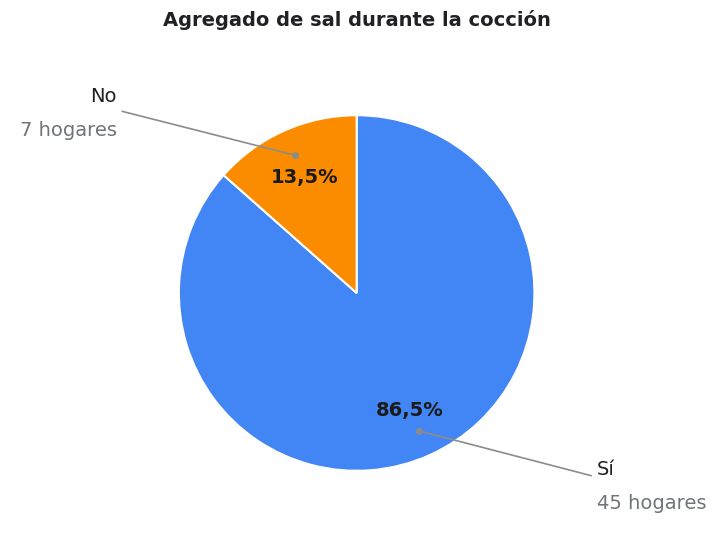

In [20]:
# Leer datos.csv si está presente en la carpeta
try:
    df_datos = pd.read_csv('datos.csv')
    print("Dataset cargado correctamente. Registros:", len(df_datos), "| Columnas:", len(df_datos.columns))
    
    # Ejemplo 1 con datos reales: 1.7 Agregado de sal (Pregunta binaria)
    col_sal = '1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?'
    if col_sal in df_datos.columns:
        conteo_sal = df_datos[col_sal].value_counts()
        print("\nFrecuencias obtenidas para uso de sal:")
        print(conteo_sal)
        
        graficar_torta(
            categorias=conteo_sal.index,
            valores=conteo_sal.values,
            titulo="Agregado de sal durante la cocción",
            unidad="hogares",
            es_binario=True
        )
except FileNotFoundError:
    print("Asegurate de que 'datos.csv' se encuentre en la misma carpeta del cuaderno.")
